## Nama: Gracia Aurelya Krisma
## NIM: H061241066
## Kelas: C

DASHBOARD ANALISIS CURAH HUJAN KALIMANTAN
Sumber: NASA POWER | Parameter: PRECTOTCORR
Mengambil data Pontianak       ... OK
Mengambil data Putussibau      ... OK
Mengambil data Palangka Raya   ... OK
Mengambil data Banjarmasin     ... OK
Mengambil data Samarinda       ... OK
Mengambil data Balikpapan      ... OK
Mengambil data Tanjung Selor   ... OK
Mengambil data Tarakan         ... OK


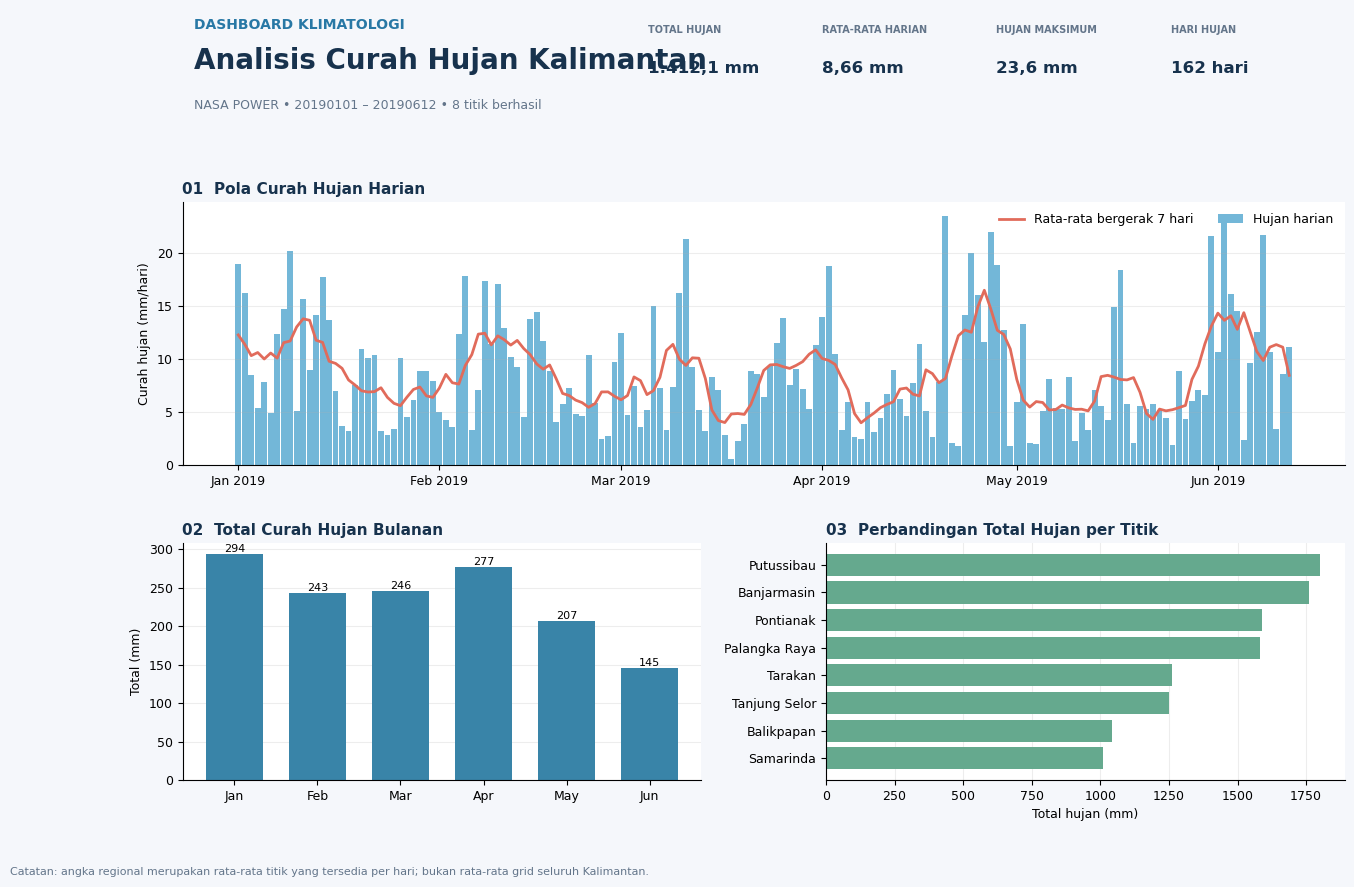

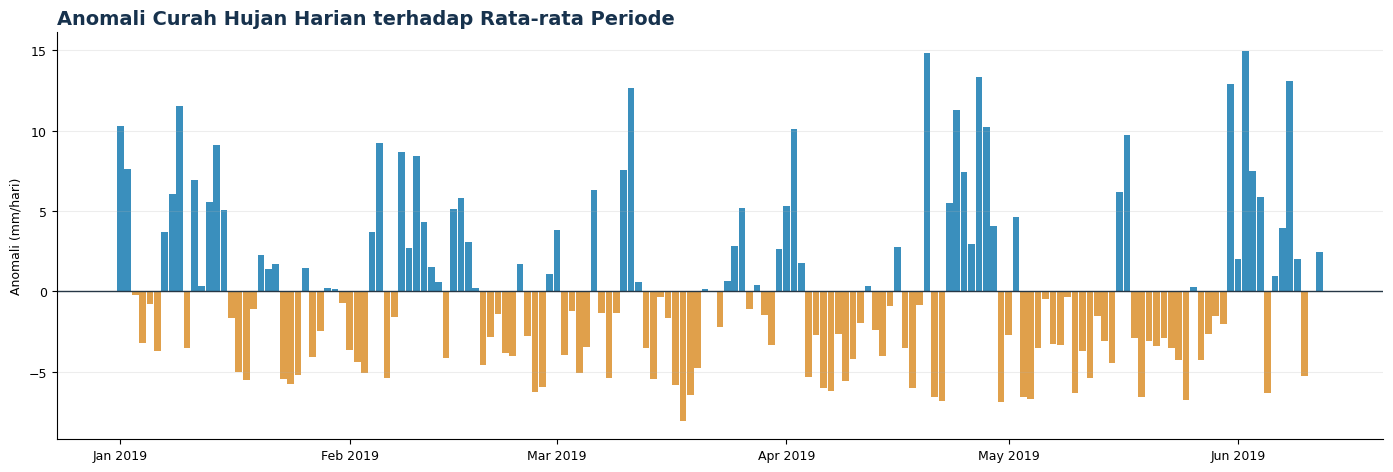

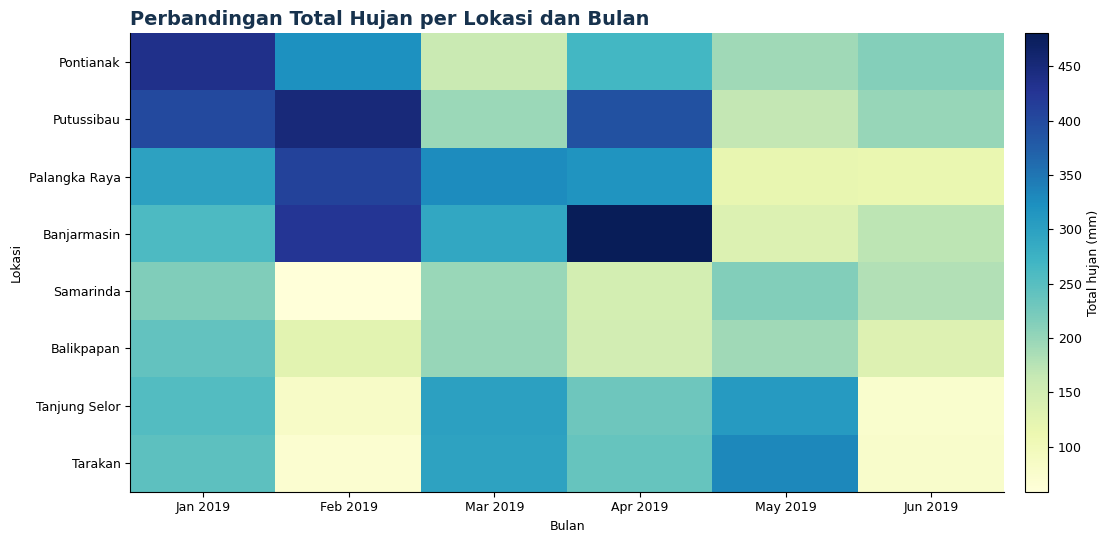


RINGKASAN STATISTIK


,Indikator,Nilai
0,Wilayah,"Kalimantan, Indonesia"
1,Tanggal awal,20190101
2,Tanggal akhir,20190612
3,Titik berhasil,8
4,Hari dalam periode,163
5,Hari dengan data,163
6,Hari tanpa data,0
7,Total curah hujan rata-rata titik (mm),1412.06
8,Rata-rata harian (mm/hari),8.66
9,Median harian (mm/hari),7.32



RINGKASAN BULANAN


,jumlah_hari,hari_valid,total_mm,rata_harian_mm,maksimum_mm,hari_hujan,persen_hari_hujan
bulan,,,,,,,
2019-01,31,31,293.64,9.47,20.19,31.0,100.00
2019-02,28,28,243.13,8.68,17.87,28.0,100.00
2019-03,31,31,245.68,7.93,21.34,30.0,96.77
2019-04,30,30,277.24,9.24,23.50,30.0,100.00
2019-05,31,31,207.13,6.68,21.56,31.0,100.00
2019-06,12,12,145.23,12.10,23.63,12.0,100.00



PERBANDINGAN LOKASI


,total_mm,rata_harian_mm,maksimum_harian_mm,hari_hujan,hari_valid,persen_hari_hujan
Putussibau,1801.51,11.05,79.31,131,163,80.37
Banjarmasin,1761.23,10.81,141.43,152,163,93.25
Pontianak,1589.42,9.75,94.33,128,163,78.53
Palangka Raya,1583.10,9.71,48.08,145,163,88.96
Tarakan,1259.36,7.73,45.81,130,163,79.75
Tanjung Selor,1249.76,7.67,52.07,138,163,84.66
Balikpapan,1040.83,6.39,76.64,138,163,84.66
Samarinda,1011.25,6.20,36.55,113,163,69.33



STATUS DATA


,lokasi,lintang,bujur,status,hari_valid
0,Pontianak,0.00,109.34,Berhasil,163
1,Putussibau,0.85,112.93,Berhasil,163
2,Palangka Raya,-2.21,113.92,Berhasil,163
3,Banjarmasin,-3.32,114.59,Berhasil,163
4,Samarinda,-0.50,117.15,Berhasil,163
5,Balikpapan,-1.27,116.83,Berhasil,163
6,Tanjung Selor,2.84,117.36,Berhasil,163
7,Tarakan,3.30,117.63,Berhasil,163



Semua hasil disimpan di:
C:\Users\HP\Downloads\Dashboard_Hujan_Kalimantan

File grafik utama: 07_dashboard_klimatologi.png


In [ ]:
"""
DASHBOARD ANALISIS CURAH HUJAN KALIMANTAN
Sumber data: NASA POWER API (PRECTOTCORR)
Periode awal: 1 Januari - 12 Juni 2019

"""

from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
import json
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# KONFIGURASI
# ============================================================
TANGGAL_AWAL = "20190101"
TANGGAL_AKHIR = "20190612"
AMBANG_HARI_HUJAN = 1.0
JENDELA_RATA_BERGERAK = 7
NAMA_WILAYAH = "Kalimantan, Indonesia"

OUTPUT = Path.home() / "Downloads" / "Dashboard_Hujan_Kalimantan"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Delapan titik sampel yang tersebar di Kalimantan Indonesia.
# Ini adalah sampel titik, bukan rata-rata spasial seluruh pulau.
LOKASI = {
    "Pontianak": (0.00, 109.34),
    "Putussibau": (0.85, 112.93),
    "Palangka Raya": (-2.21, 113.92),
    "Banjarmasin": (-3.32, 114.59),
    "Samarinda": (-0.50, 117.15),
    "Balikpapan": (-1.27, 116.83),
    "Tanjung Selor": (2.84, 117.36),
    "Tarakan": (3.30, 117.63),
}
API_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"


# ============================================================
# FUNGSI PENGAMBILAN DATA
# ============================================================
def ambil_data_lokasi(nama, lat, lon):
    params = {
        "parameters": "PRECTOTCORR",
        "community": "AG",
        "longitude": lon,
        "latitude": lat,
        "start": TANGGAL_AWAL,
        "end": TANGGAL_AKHIR,
        "format": "JSON",
        "time-standard": "LST",
    }
    response = requests.get(API_URL, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()

    try:
        values = payload["properties"]["parameter"]["PRECTOTCORR"]
    except (KeyError, TypeError):
        raise ValueError("Struktur data NASA POWER tidak sesuai.")

    series = pd.Series(values, name=nama, dtype="float64")
    series.index = pd.to_datetime(series.index, format="%Y%m%d")
    series = series.replace(-999, np.nan)
    series[series < 0] = np.nan
    series.index.name = "tanggal"
    return series


def format_angka(x, desimal=1):
    if pd.isna(x):
        return "—"
    return f"{x:,.{desimal}f}".replace(",", "X").replace(".", ",").replace("X", ".")


# ============================================================
# AMBIL DATA SEMUA TITIK
# ============================================================
print("=" * 68)
print("DASHBOARD ANALISIS CURAH HUJAN KALIMANTAN")
print("Sumber: NASA POWER | Parameter: PRECTOTCORR")
print("=" * 68)

seri_lokasi = {}
status_lokasi = []

for nama, (lat, lon) in LOKASI.items():
    print(f"Mengambil data {nama:15s} ...", end=" ")
    try:
        seri_lokasi[nama] = ambil_data_lokasi(nama, lat, lon)
        status_lokasi.append({
            "lokasi": nama, "lintang": lat, "bujur": lon,
            "status": "Berhasil", "hari_valid": int(seri_lokasi[nama].notna().sum())
        })
        print("OK")
    except Exception as e:
        status_lokasi.append({
            "lokasi": nama, "lintang": lat, "bujur": lon,
            "status": f"Gagal: {str(e)[:100]}", "hari_valid": 0
        })
        print("GAGAL")

if not seri_lokasi:
    raise RuntimeError(
        "Semua permintaan data gagal. Periksa koneksi internet, "
        "kemudian jalankan ulang program."
    )

rentang = pd.date_range(TANGGAL_AWAL, TANGGAL_AKHIR, freq="D")
per_lokasi = pd.concat(seri_lokasi.values(), axis=1).reindex(rentang)
per_lokasi.index.name = "tanggal"

# Rata-rata antar titik tersedia setiap hari.
# Jumlah titik valid disimpan agar representasi data transparan.
df = pd.DataFrame(index=rentang)
df.index.name = "tanggal"
df["hujan_mm"] = per_lokasi.mean(axis=1)
df["titik_valid"] = per_lokasi.count(axis=1)
df["YEAR"] = df.index.year
df["DOY"] = df.index.dayofyear
df["bulan"] = df.index.to_period("M").astype(str)

df["hari_hujan"] = np.where(
    df["hujan_mm"].notna(),
    (df["hujan_mm"] >= AMBANG_HARI_HUJAN).astype(float),
    np.nan
)
df["rata_bergerak"] = df["hujan_mm"].rolling(
    JENDELA_RATA_BERGERAK, center=True, min_periods=3
).mean()
df["anomali_mm"] = df["hujan_mm"] - df["hujan_mm"].mean()
df["kumulatif_mm"] = df["hujan_mm"].cumsum()

df["kategori"] = pd.cut(
    df["hujan_mm"],
    bins=[-np.inf, 0.5, 20, 50, 100, np.inf],
    labels=["Tidak hujan", "Ringan–sedang", "Lebat", "Sangat lebat", "Ekstrem"],
    right=False
)

# ============================================================
# RINGKASAN BULANAN DAN LOKASI
# ============================================================
bulanan = df.groupby("bulan", observed=False).agg(
    jumlah_hari=("hujan_mm", "size"),
    hari_valid=("hujan_mm", "count"),
    total_mm=("hujan_mm", "sum"),
    rata_harian_mm=("hujan_mm", "mean"),
    maksimum_mm=("hujan_mm", "max"),
    hari_hujan=("hari_hujan", "sum")
)
bulanan.loc[bulanan["hari_valid"] == 0, "total_mm"] = np.nan
bulanan["persen_hari_hujan"] = (
    bulanan["hari_hujan"] / bulanan["hari_valid"].replace(0, np.nan) * 100
)

ringkas_lokasi = pd.DataFrame({
    "total_mm": per_lokasi.sum(min_count=1),
    "rata_harian_mm": per_lokasi.mean(),
    "maksimum_harian_mm": per_lokasi.max(),
    "hari_hujan": (per_lokasi >= AMBANG_HARI_HUJAN).sum(),
    "hari_valid": per_lokasi.count()
})
ringkas_lokasi["persen_hari_hujan"] = (
    ringkas_lokasi["hari_hujan"] /
    ringkas_lokasi["hari_valid"].replace(0, np.nan) * 100
)
ringkas_lokasi = ringkas_lokasi.sort_values("total_mm", ascending=False)

total_hujan = df["hujan_mm"].sum(min_count=1)
rata_hujan = df["hujan_mm"].mean()
maks_hujan = df["hujan_mm"].max()
tgl_maks = df["hujan_mm"].idxmax() if df["hujan_mm"].notna().any() else pd.NaT
hari_hujan_total = int(df["hari_hujan"].sum()) if df["hari_hujan"].notna().any() else 0
hari_valid_total = int(df["hujan_mm"].count())
tanggal_hilang = int(df["hujan_mm"].isna().sum())
persen_hari_hujan = (
    df["hari_hujan"].mean() * 100 if df["hari_hujan"].notna().any() else np.nan
)

ringkasan = pd.DataFrame({
    "Indikator": [
        "Wilayah", "Tanggal awal", "Tanggal akhir", "Titik berhasil",
        "Hari dalam periode", "Hari dengan data", "Hari tanpa data",
        "Total curah hujan rata-rata titik (mm)",
        "Rata-rata harian (mm/hari)", "Median harian (mm/hari)",
        "Standar deviasi (mm)", "Maksimum harian (mm)",
        "Tanggal maksimum", "Hari hujan (>= 1 mm)",
        "Persentase hari hujan (%)"
    ],
    "Nilai": [
        NAMA_WILAYAH, TANGGAL_AWAL, TANGGAL_AKHIR, len(seri_lokasi),
        len(df), hari_valid_total, tanggal_hilang,
        round(total_hujan, 2) if pd.notna(total_hujan) else np.nan,
        round(rata_hujan, 2) if pd.notna(rata_hujan) else np.nan,
        round(df["hujan_mm"].median(), 2),
        round(df["hujan_mm"].std(), 2),
        round(maks_hujan, 2) if pd.notna(maks_hujan) else np.nan,
        str(tgl_maks.date()) if pd.notna(tgl_maks) else "—",
        hari_hujan_total, round(persen_hari_hujan, 1)
    ]
})

# ============================================================
# SIMPAN DATA HASIL
# ============================================================
df.to_csv(OUTPUT / "01_hujan_harian_regional.csv", float_format="%.3f")
per_lokasi.to_csv(OUTPUT / "02_hujan_harian_per_lokasi.csv", float_format="%.3f")
bulanan.round(2).to_csv(OUTPUT / "03_ringkasan_bulanan.csv")
ringkas_lokasi.round(2).to_csv(OUTPUT / "04_perbandingan_lokasi.csv")
ringkasan.to_csv(OUTPUT / "05_ringkasan_statistik.csv", index=False)
pd.DataFrame(status_lokasi).to_csv(OUTPUT / "06_status_pengambilan_data.csv", index=False)

# ============================================================
# GRAFIK 1: DASHBOARD RINGKASAN 4 PANEL
# ============================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "figure.titlesize": 17,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig = plt.figure(figsize=(15, 10), facecolor="#f5f7fb")
gs = fig.add_gridspec(3, 2, height_ratios=[0.65, 1.5, 1.35], hspace=0.38, wspace=0.24)

# Header dan kartu KPI
ax_head = fig.add_subplot(gs[0, :])
ax_head.axis("off")
ax_head.text(0.01, 0.83, "DASHBOARD KLIMATOLOGI", fontsize=10,
             color="#2878a5", fontweight="bold", transform=ax_head.transAxes)
ax_head.text(0.01, 0.48, "Analisis Curah Hujan Kalimantan",
             fontsize=20, fontweight="bold", color="#17324d",
             transform=ax_head.transAxes)
ax_head.text(0.01, 0.13,
             f"NASA POWER • {TANGGAL_AWAL} – {TANGGAL_AKHIR} • {len(seri_lokasi)} titik berhasil",
             fontsize=9, color="#63758a", transform=ax_head.transAxes)

kpis = [
    ("TOTAL HUJAN", f"{format_angka(total_hujan)} mm"),
    ("RATA-RATA HARIAN", f"{format_angka(rata_hujan, 2)} mm"),
    ("HUJAN MAKSIMUM", f"{format_angka(maks_hujan)} mm"),
    ("HARI HUJAN", f"{hari_hujan_total} hari"),
]
for i, (judul, nilai) in enumerate(kpis):
    x = 0.40 + i * 0.15
    ax_head.text(x, 0.80, judul, fontsize=7, color="#63758a",
                 transform=ax_head.transAxes, fontweight="bold")
    ax_head.text(x, 0.45, nilai, fontsize=12, color="#17324d",
                 transform=ax_head.transAxes, fontweight="bold")

# Panel A: deret waktu harian
ax1 = fig.add_subplot(gs[1, :])
ax1.set_facecolor("white")
ax1.bar(df.index, df["hujan_mm"], color="#73b7d8", width=0.9, label="Hujan harian")
ax1.plot(df.index, df["rata_bergerak"], color="#e16b5b", linewidth=2,
         label=f"Rata-rata bergerak {JENDELA_RATA_BERGERAK} hari")
ax1.set_title("01  Pola Curah Hujan Harian", loc="left", fontweight="bold", color="#17324d")
ax1.set_ylabel("Curah hujan (mm/hari)")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.grid(axis="y", alpha=0.22)
ax1.legend(frameon=False, ncol=2, loc="upper right")

# Panel B: total bulanan
ax2 = fig.add_subplot(gs[2, 0])
ax2.set_facecolor("white")
bulan_labels = [pd.Period(x).strftime("%b") for x in bulanan.index]
bars = ax2.bar(bulan_labels, bulanan["total_mm"], color="#3984a8", width=0.68)
ax2.set_title("02  Total Curah Hujan Bulanan", loc="left", fontweight="bold", color="#17324d")
ax2.set_ylabel("Total (mm)")
ax2.grid(axis="y", alpha=0.22)
ax2.set_axisbelow(True)
for bar, val in zip(bars, bulanan["total_mm"]):
    if pd.notna(val):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 format_angka(val, 0), ha="center", va="bottom", fontsize=8)

# Panel C: perbandingan titik
ax3 = fig.add_subplot(gs[2, 1])
ax3.set_facecolor("white")
lok_plot = ringkas_lokasi.sort_values("total_mm", ascending=True)
bars2 = ax3.barh(lok_plot.index, lok_plot["total_mm"], color="#65a98e")
ax3.set_title("03  Perbandingan Total Hujan per Titik", loc="left",
              fontweight="bold", color="#17324d")
ax3.set_xlabel("Total hujan (mm)")
ax3.grid(axis="x", alpha=0.22)
ax3.set_axisbelow(True)

fig.text(0.01, 0.015,
         "Catatan: angka regional merupakan rata-rata titik yang tersedia per hari; bukan rata-rata grid seluruh Kalimantan.",
         fontsize=8, color="#63758a")
fig.savefig(OUTPUT / "07_dashboard_klimatologi.png", dpi=180,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

# ============================================================
# GRAFIK 2: ANOMALI HUJAN
# ============================================================
fig2, ax = plt.subplots(figsize=(14, 4.8), facecolor="white")
warna = np.where(df["anomali_mm"] >= 0, "#3a8fbd", "#e0a04b")
ax.bar(df.index, df["anomali_mm"], color=warna, width=0.9)
ax.axhline(0, color="#263746", linewidth=1)
ax.set_title("Anomali Curah Hujan Harian terhadap Rata-rata Periode",
             loc="left", fontsize=14, fontweight="bold", color="#17324d")
ax.set_ylabel("Anomali (mm/hari)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="y", alpha=0.22)
fig2.tight_layout()
fig2.savefig(OUTPUT / "08_anomali_hujan.png", dpi=180, bbox_inches="tight")
plt.show()

# ============================================================
# GRAFIK 3: PETA PANAS LOKASI VS BULAN
# ============================================================
bulanan_lokasi = per_lokasi.copy()
bulanan_lokasi["bulan"] = bulanan_lokasi.index.to_period("M").astype(str)
heat = bulanan_lokasi.groupby("bulan").sum(min_count=1).T

fig3, ax = plt.subplots(figsize=(12, 5.5), facecolor="white")
im = ax.imshow(heat.values, aspect="auto", cmap="YlGnBu")
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels([pd.Period(x).strftime("%b %Y") for x in heat.columns])
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_title("Perbandingan Total Hujan per Lokasi dan Bulan",
             loc="left", fontsize=14, fontweight="bold", color="#17324d")
cb = fig3.colorbar(im, ax=ax, pad=0.02)
cb.set_label("Total hujan (mm)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Lokasi")
fig3.tight_layout()
fig3.savefig(OUTPUT / "09_heatmap_lokasi_bulanan.png", dpi=180, bbox_inches="tight")
plt.show()

# ============================================================
# LAPORAN AKHIR
# ============================================================
print("\n" + "=" * 68)
print("RINGKASAN STATISTIK")
print("=" * 68)
display(ringkasan)

print("\nRINGKASAN BULANAN")
display(bulanan.round(2))

print("\nPERBANDINGAN LOKASI")
display(ringkas_lokasi.round(2))

print("\nSTATUS DATA")
display(pd.DataFrame(status_lokasi))

print("\nSemua hasil disimpan di:")
print(OUTPUT.resolve())
print("\nFile grafik utama: 07_dashboard_klimatologi.png")
